# Example of the aitlas toolbox in the context of semantic segmentation

This notebook shows a sample implementation of semantic segmentation using the aitlas toolbox. The SpaceNet-4 data contains several images taken over the same areas with different viewing angles. Each of these is associated to the same label file.

## Import the required packages

In [ ]:
from aitlas.datasets import SpaceNet4Dataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor
import numpy as np

## Visualize images and masks

In [ ]:
dataset_config = {
    "data_dir" : "./data/spacenet_4/train/AOI_6_Atlanta/",
}
dataset = SpaceNet4Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 28728


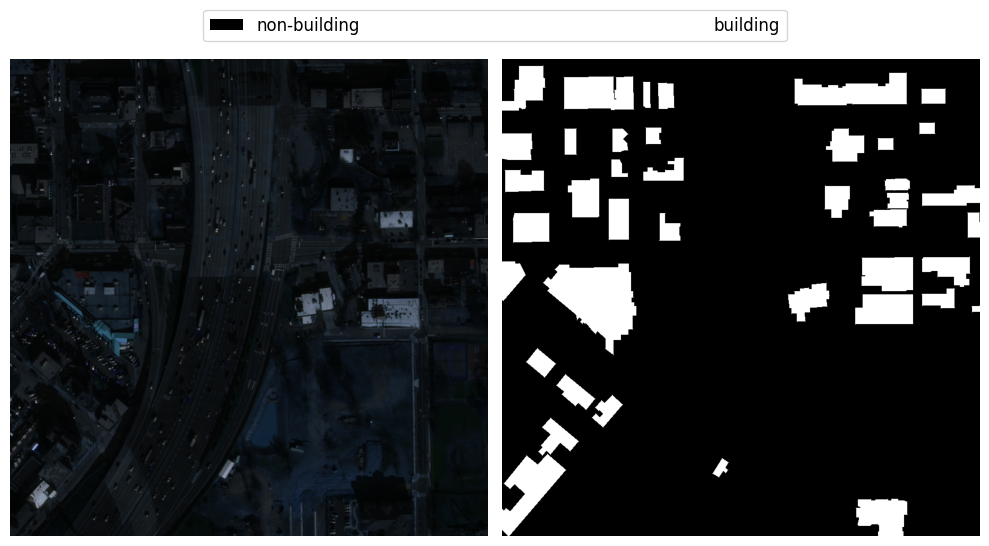

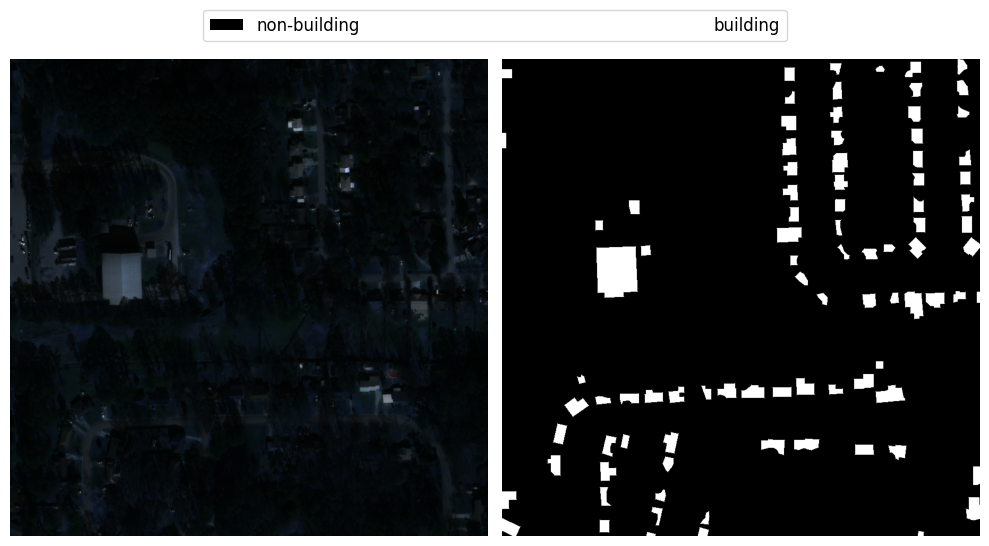

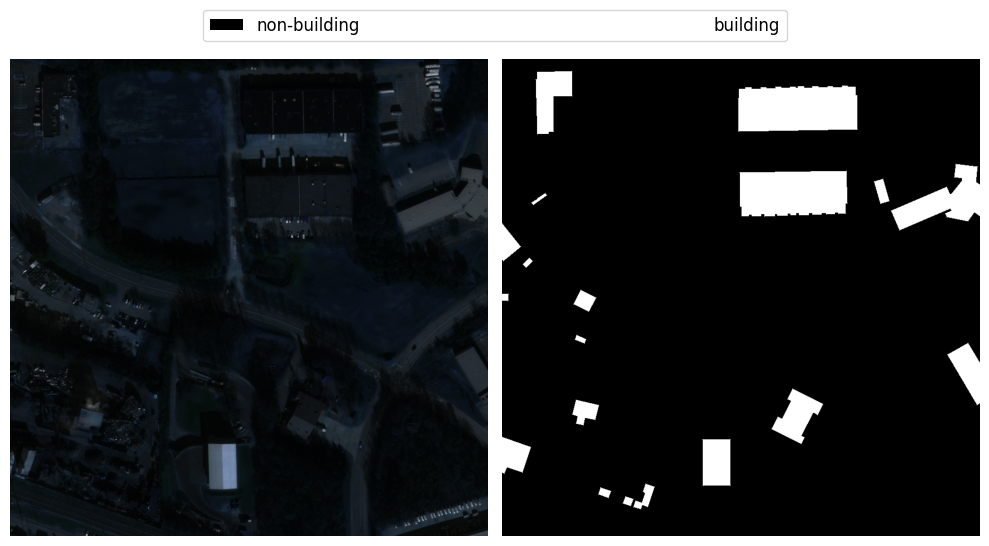

In [11]:
dataset.show_image(0);
dataset.show_image(1);
dataset.show_image(12);

In [108]:
dataset.data_distribution_table()

,Number of pixels
non-building,777494555.0
building,84345445.0


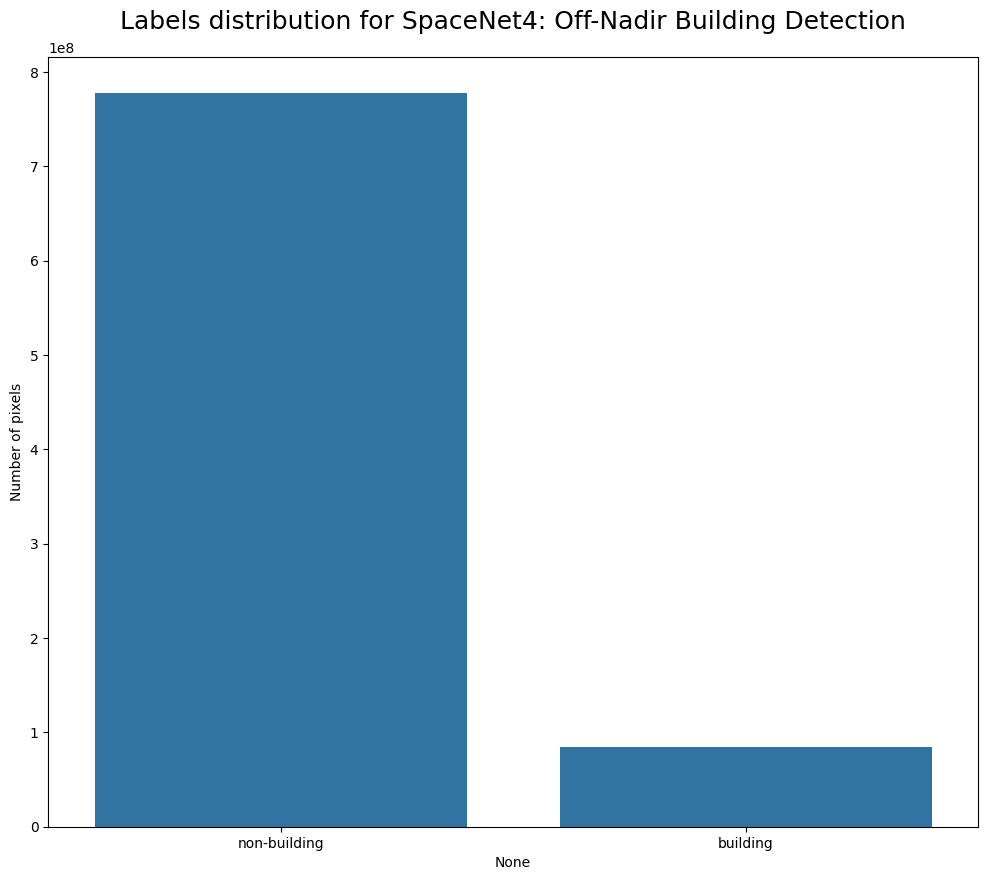

In [109]:
dataset.data_distribution_barchart();

## Load training data ##

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/spacenet_4/train/AOI_6_Atlanta/",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = SpaceNet4Dataset(train_dataset_config)

len(train_dataset)

28728

## Create the model ##

In [ ]:
epochs = 10
model_directory = "./data/experiments/SpaceNet4/"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training ##

In [14]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-10-14 06:45:30,016 INFO Starting training.
training: 100%|██████████| 1796/1796 [15:03<00:00,  1.99it/s]
2025-10-14 07:00:33,485 INFO epoch: 1, time: 903, loss:  0.14515
testing on train set: 100%|██████████| 1796/1796 [15:27<00:00,  1.94it/s]
2025-10-14 07:16:03,439 INFO IOU:0.8114252698337338, IOU mean:0.43388691442452976, IOU per Class:[0.86777383 0.        ]
training: 100%|██████████| 1796/1796 [15:29<00:00,  1.93it/s]
2025-10-14 07:31:32,693 INFO epoch: 2, time: 929, loss:  0.09902
testing on train set: 100%|██████████| 1796/1796 [15:21<00:00,  1.95it/s]
2025-10-14 07:46:54,548 INFO IOU:0.8114252698337338, IOU mean:0.43388691442452976, IOU per Class:[0.86777383 0.        ]
training: 100%|██████████| 1796/1796 [15:14<00:00,  1.96it/s]
2025-10-14 08:02:09,460 INFO epoch: 3, time: 915, loss:  0.09824
testing on train set: 100%|██████████| 1796/1796 [15:01<00:00,  1.99it/s]
2025-10-14 08:17:10,868 INFO IOU:0.8114252698337338, IOU mean:0.43388691442452976, IOU per Class:[0.8677738

0.09800483323312079

## Predictions ##

2025-10-14 11:50:15,958 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/SpaceNet4/checkpoint.pth.tar
2025-10-14 11:50:16,266 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/SpaceNet4/checkpoint.pth.tar at epoch 11


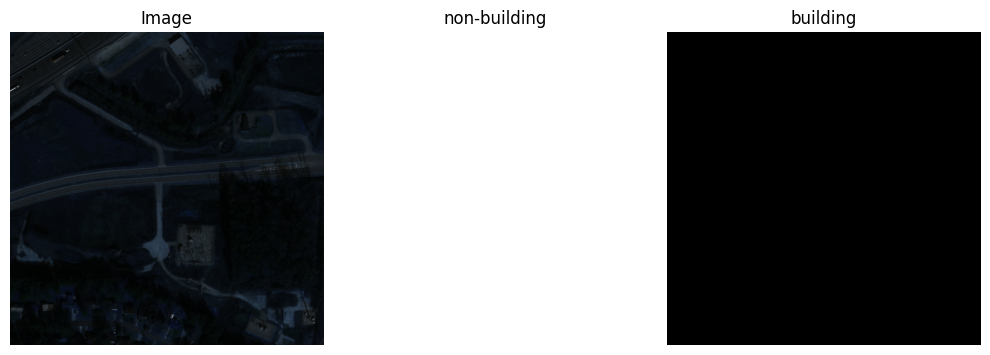

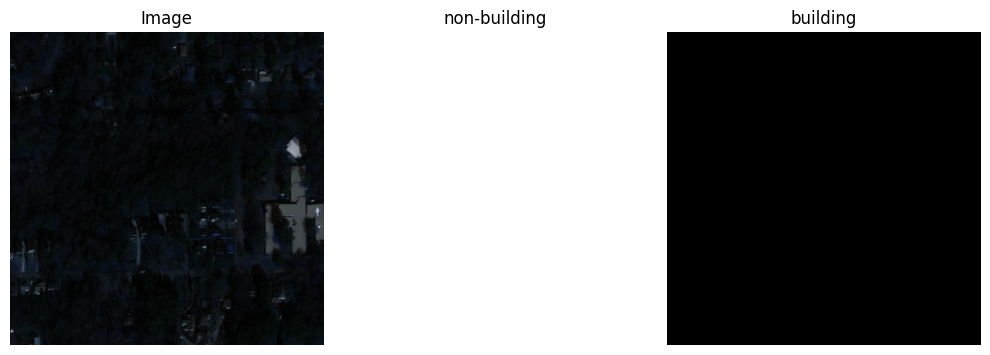

In [ ]:
model_path = "./data/experiments/SpaceNet4/checkpoint.pth.tar"
labels = ["non-building","building"]
transform = ResizeToTensor()
model.load_model(model_path)

image = image_loader('./data/spacenet_4/test_public/AOI_6_Atlanta/nadir14_catid_10300100039AB000/PS-RGBNIR/SN4_buildings_test_public_AOI_6_Atlanta_nadir14_catid_10300100039AB000_PS-RGBNIR_738101_3722439.tif')[:,:,:3]
image = ((image - image.min()) / (image.max() - image.min())).astype(np.float32)
fig = model.predict_masks(image, labels, transform)
image = image_loader('./data/spacenet_4/test_public/AOI_6_Atlanta/nadir27_catid_1030010003472200/PS-RGBNIR/SN4_buildings_test_public_AOI_6_Atlanta_nadir27_catid_1030010003472200_PS-RGBNIR_745751_3734589.tif')[:,:,:3]
image = ((image - image.min()) / (image.max() - image.min())).astype(np.float32)
fig = model.predict_masks(image, labels, transform)